# Pixl: placement on drawn scenes

The position score in training compares caption losses on real scenes; this notebook checks what the model **draws**. Run it with the kernel's working directory set to `notebooks/analysis/`.

For each scored caption, every run in `RUNS` draws `SAMPLES` images per guidance value, sample *s* from seed *s*, at the model module's `TEMPERATURE` and `TOP_K`. Each 16×16 quadrant of a drawing is compared with pictures of the caption's four objects. A caption names labels, and many labels have several sprites in a pack, so each object's pictures are every sprite of its pack and label, centred over the scene's background tile as the scene generator draws them. A drawn quadrant matches the object with the picture that agrees with it on the largest share of the pixels where either differs from the background, when that share is at least `MATCH`:

| Label | Meaning |
|---|---|
| correct | it matches the object the caption puts there |
| swapped | it matches another of the caption's objects |
| other | it matches none of them: a wrong object, an empty quadrant or noise |

With the right four objects in random quadrants, chance is 0.25 correct per quadrant and 1/24 (0.042) for all four. The scored scenes are the first `PER_KIND` of each kind: train scenes from the train split, new sprites and new pairs from the test split.

In [1]:
import os

# Apple GPU memory, relative to the recommended maximum (19.1 GB on the measured 25.8 GB Mac). The
# allocator keeps freed blocks until use passes the low watermark, by default 1.4x: more than the RAM.
# Drawing's key-value caches grow by one pixel each step, so the freed blocks are too small to reuse
# and pile up. Drawing BATCH = 64 captions with guidance needs about 4 GB: collect freed blocks above
# 0.3x (about 6 GB) and fail above 0.5x (about 10 GB); raise both with BATCH. Set before torch starts
# its allocator: restart the kernel after changing them.
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.5")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.3")

import textwrap
import time
from collections import defaultdict
from dataclasses import dataclass
from functools import cache
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import display
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from tqdm.auto import tqdm

from pixl.data import PLACES, REPO, SIZE, load
from pixl.model import TEMPERATURE, TOP_K, EncoderPixl, encode_captions
from pixl.preprocess import TRANSPARENT, decode, encode, load_palette
from pixl.tokenizer import Tokenizer
from pixl.train import KINDS, clock, load_model, pick_device

PALETTE = load_palette()
# Side of a quadrant, which holds one object.
SLOT = SIZE // 2
# Packs drawn at 32 px, whose sprites the scene generator halves (HALVED in scripts/scenes/generate.py).
HALVED = {"dcss_dungeon-crawl-32x32"}
# Outline colour of each label in the drawing test.
COLOURS = {"correct": "limegreen", "swapped": "orange", "other": "red"}


@dataclass
class Scenes:
    """The scored scenes.

    Attributes:
        tokens: (n, 32, 32) palette tokens of the real scenes.
        captions: Each scene's caption.
        kinds: Each scene's kind, one of KINDS.
        backgrounds: (n, 16, 16) tokens of each scene's background tile; TRANSPARENT without one.
        pictures: (n, 4, variants, 16, 16) tokens of the object the caption puts in each
            quadrant, as every sprite of its pack and label over the background tile; objects
            with fewer sprites repeat their first.
    """

    tokens: np.ndarray
    captions: list[str]
    kinds: np.ndarray
    backgrounds: np.ndarray
    pictures: np.ndarray


def quadrants(grids: np.ndarray) -> np.ndarray:
    """Splits (..., 32, 32) grids into (..., 4, 16, 16) quadrants, in PLACES order."""
    *lead, height, width = grids.shape
    halves = grids.reshape(*lead, 2, height // 2, 2, width // 2).swapaxes(-3, -2)
    return halves.reshape(*lead, 4, height // 2, width // 2)


def library() -> tuple[dict[str, Image.Image], dict[str, list[str]]]:
    """Every sprite of both splits as the scene generator places it, and its variants.

    Returns:
        Path -> RGBA sprite, halved for the HALVED packs; and path -> the paths of every
        sprite of its pack and label that fits a quadrant.
    """
    rows = load_dataset(REPO, "sprites", split="train+test").select_columns(["path", "pack", "label", "image"])[:]
    images: dict[str, Image.Image] = {}
    keys: dict[str, tuple[str, str]] = {}
    groups: dict[tuple[str, str], list[str]] = defaultdict(list)
    for path, pack, label, image in zip(rows["path"], rows["pack"], rows["label"], rows["image"], strict=True):
        image = image.convert("RGBA")
        if pack in HALVED:
            image = image.resize((image.width // 2, image.height // 2), Image.Resampling.NEAREST)
        images[path], keys[path] = image, (pack, label)
        if max(image.size) <= SLOT:
            groups[pack, label].append(path)
    return images, {path: groups[key] for path, key in keys.items()}


def eval_scenes(per_kind: int) -> Scenes:
    """The first per_kind scenes of each kind, with their background tiles and object pictures."""
    keep = ("kind", "background_path", "sprites", "slots")
    splits = [load(f"train[:{per_kind}]", keep=keep)[:], load("test", keep=keep)[:]]
    tokens = np.concatenate([split["tokens"].numpy() for split in splits])
    column = {name: [value for split in splits for value in split[name]] for name in ("caption", *keep)}
    kinds = np.array(column["kind"])
    rows = np.concatenate([np.flatnonzero(kinds == kind)[:per_kind] for kind in KINDS])
    images, variants = library()

    @cache
    def picture(background: str, sprite: str) -> np.ndarray:
        """(16, 16) tokens of a sprite centred over a background tile, or over nothing for ""."""
        canvas = images[background].copy() if background else Image.new("RGBA", (SLOT, SLOT), (0, 0, 0, 0))
        image = images[sprite]
        canvas.alpha_composite(image, ((SLOT - image.width) // 2, (SLOT - image.height) // 2))
        return encode(canvas, PALETTE)

    blank = np.full((SLOT, SLOT), TRANSPARENT, np.uint8)
    backgrounds, pictures = [], []
    for i in rows:
        background = column["background_path"][i]
        backgrounds.append(encode(images[background], PALETTE) if background else blank)
        # Each object's "row,column" slot, in caption order like its sprite path.
        placed = dict(zip(column["slots"][i].split("|"), column["sprites"][i].split("|"), strict=True))
        pictures.append([[picture(background, path) for path in variants[placed[f"{r},{c}"]]] for r in (0, 1) for c in (0, 1)])
    most = max(len(sprites) for scene in pictures for sprites in scene)
    return Scenes(
        tokens=tokens[rows],
        captions=[column["caption"][i] for i in rows],
        kinds=kinds[rows],
        backgrounds=np.stack(backgrounds),
        pictures=np.array([[sprites + sprites[:1] * (most - len(sprites)) for sprites in scene] for scene in pictures]),
    )


def scores(drawn: np.ndarray, pictures: np.ndarray, backgrounds: np.ndarray) -> np.ndarray:
    """How well each drawn quadrant matches each object the caption names.

    Args:
        drawn: (samples, scenes, 4, 16, 16) quadrants of the drawings.
        pictures: (scenes, 4, variants, 16, 16) pictures of the object each caption puts
            in each quadrant (Scenes.pictures).
        backgrounds: (scenes, 16, 16) background tile tokens.

    Returns:
        (samples, scenes, drawn quadrant, object): for the object's best-matching picture,
        the share of matching pixels among those where the drawn quadrant or the picture
        differs from the background.
    """
    background = backgrounds[:, None]
    drawn_shape = (drawn != background)[:, :, :, None]
    score = np.zeros(drawn.shape[:3] + (4,))
    for variant in np.moveaxis(pictures, 2, 0):
        region = drawn_shape | (variant != background)[:, None]
        same = drawn[:, :, :, None] == variant[:, None]
        score = np.maximum(score, (same & region).sum((-2, -1)) / np.maximum(region.sum((-2, -1)), 1))
    return score


def classify(score: np.ndarray, match: float) -> tuple[np.ndarray, np.ndarray]:
    """Tells which drawn quadrants hold the right object, and which another named one.

    Args:
        score: (samples, scenes, 4, 4) from scores().
        match: Least score for an object to count.

    Returns:
        (samples, scenes, 4) masks of the correct and the swapped quadrants; the others
        match no object.
    """
    best, matched = score.argmax(-1), score.max(-1) >= match
    right = best == np.arange(4)
    return matched & right, matched & ~right


def check(scenes: Scenes, match: float) -> None:
    """Stops unless the real scenes score correct and their quadrants moved one place score swapped."""
    real = quadrants(scenes.tokens)
    correct, _ = classify(scores(real[None], scenes.pictures, scenes.backgrounds), match)
    _, swapped = classify(scores(np.roll(real, 1, axis=1)[None], scenes.pictures, scenes.backgrounds), match)
    print(f"check: real scenes {correct.mean():.4f} correct, quadrants moved one place {swapped.mean():.4f} swapped")
    # Two objects of one scene with identical pictures would tie; anything more is a bug.
    if min(correct.mean(), swapped.mean()) < 0.99:
        raise RuntimeError("the comparison does not recognise the real scenes; check the sprite pictures")


def draw(
    model: EncoderPixl, captions: list[str], guidance: float, samples: int, batch: int, progress: tqdm | None = None
) -> np.ndarray:
    """(samples, len(captions), 32, 32) drawings; sample s is drawn from seed s.

    Each finished batch advances progress, if given, by its drawings.
    """
    device = next(model.parameters()).device
    ids = encode_captions(captions, Tokenizer.load(), length=model.config.caption)
    side = model.config.side
    drawn = np.empty((samples, len(captions), side, side), np.uint8)
    for sample in range(samples):
        torch.manual_seed(sample)
        for start in range(0, len(captions), batch):
            pixels = model.generate(
                ids[start : start + batch].to(device), temperature=TEMPERATURE, top_k=TOP_K, guidance=guidance
            )
            drawn[sample, start : start + batch] = pixels.view(-1, side, side).cpu().numpy()
            if progress is not None:
                progress.update(len(pixels))
            if device.type == "mps":
                torch.mps.empty_cache()  # give the finished batch's caches back to the system
    return drawn


def summary(correct: np.ndarray, swapped: np.ndarray, kinds: np.ndarray) -> list[dict[str, float | int | str]]:
    """One table row per kind: shares of correct, swapped and other quadrants, all four correct, and each place."""
    rows: list[dict[str, float | int | str]] = []
    for kind in KINDS:
        right, moved = correct[:, kinds == kind], swapped[:, kinds == kind]
        rows.append({
            "kind": kind,
            "drawings": right.shape[0] * right.shape[1],
            "correct": right.mean(),
            "swapped": moved.mean(),
            "other": 1 - right.mean() - moved.mean(),
            "all four": right.all(-1).mean(),
            **{place: right[..., i].mean() for i, place in enumerate(PLACES)},
        })
    return rows


def show(real: np.ndarray, drawn: np.ndarray, correct: np.ndarray, swapped: np.ndarray, captions: list[str], title: str) -> None:
    """Draws real scenes above their drawings, each drawn quadrant outlined in its label's colour.

    Args:
        real: (n, 32, 32) tokens of the real scenes.
        drawn: (n, 32, 32) tokens of the drawings.
        correct: (n, 4) correct quadrants of the drawings.
        swapped: (n, 4) swapped quadrants of the drawings.
        captions: Each scene's caption, written above it.
        title: Figure title.
    """
    figure, axes = plt.subplots(2, len(real), figsize=(2.6 * len(real), 6.5), squeeze=False)
    for column, text in enumerate(captions):
        for row, images in enumerate((real, drawn)):
            axes[row, column].imshow(decode(images[column], PALETTE), interpolation="nearest")
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
        axes[0, column].set_title(textwrap.fill(text, 34), fontsize=7)
        for i in range(4):
            label = "correct" if correct[column, i] else "swapped" if swapped[column, i] else "other"
            top, left = divmod(i, 2)
            # Pixel edges sit at half-integers; the inset keeps neighbouring outlines apart.
            corner = (left * SLOT - 0.1, top * SLOT - 0.1)
            axes[1, column].add_patch(Rectangle(corner, SLOT - 0.8, SLOT - 0.8, fill=False, edgecolor=COLOURS[label], linewidth=2))
    axes[0, 0].set_ylabel("real")
    axes[1, 0].set_ylabel("drawn")
    figure.suptitle(f"{title} (outline: {', '.join(f'{colour} {label}' for label, colour in COLOURS.items())})")
    figure.tight_layout()
    plt.show()

## Settings

The defaults score 250 scenes of each kind; the review asks for every test scene (`PER_KIND = 1000`). The sweep's cost is its number of drawings, `len(RUNS) × len(GUIDANCES) × SAMPLES × 3 × PER_KIND`, each 1,024 steps; guidance other than 1 runs every row twice. The drawing test below measures the speed and estimates the sweep's time.

In [2]:
ROOT = Path("..", "..")  # the project, from notebooks/analysis/
RUNS = ["scenes-four", "scenes-four-margin", "scenes-four-margin-2ep"]  # folders in checkpoints/
GUIDANCES = [1.0, 2.0, 3.0, 5.0]
SAMPLES = 4  # drawings per caption; sample s is drawn from seed s
PER_KIND = 250  # scenes of each kind
MATCH = 0.5  # least share of matching pixels for a drawn quadrant to count as an object
BATCH = 64  # captions drawn at once
DEVICE = "auto"  # "auto": CUDA, then Apple's GPU, then the CPU
CPU_THREADS = 4
TEST_RUN, TEST_GUIDANCE, TEST_SCENES = "scenes-four-margin-2ep", 3.0, 4  # the drawing test: scenes of each kind
OUT = ROOT.joinpath("runs", "placement")  # saved drawings and placement.csv

if DEVICE == "cpu":
    # A few threads, and this kernel at the lowest priority until it restarts, so the Mac stays responsive.
    torch.set_num_threads(CPU_THREADS)
    os.nice(max(0, 19 - os.nice(0)))
device = pick_device(DEVICE)

## Scenes

Loads the scored scenes, their background tiles and their objects' pictures, then checks the comparison: the real scenes must score correct, and their quadrants moved one place must score swapped.

In [3]:
scenes = eval_scenes(PER_KIND)
print(f"{len(scenes.captions):,} scenes; up to {scenes.pictures.shape[2]} sprites per object")
check(scenes, MATCH)

750 scenes; up to 20 sprites per object
check: real scenes 1.0000 correct, quadrants moved one place 1.0000 swapped


## Drawing test

Draws the first `TEST_SCENES` scenes of each kind with `TEST_RUN` at `TEST_GUIDANCE`, seed 0, and shows each real scene above its drawing, with every drawn quadrant outlined by its label. Check that the labels agree with your eye before trusting the table, and change `MATCH` if they do not.

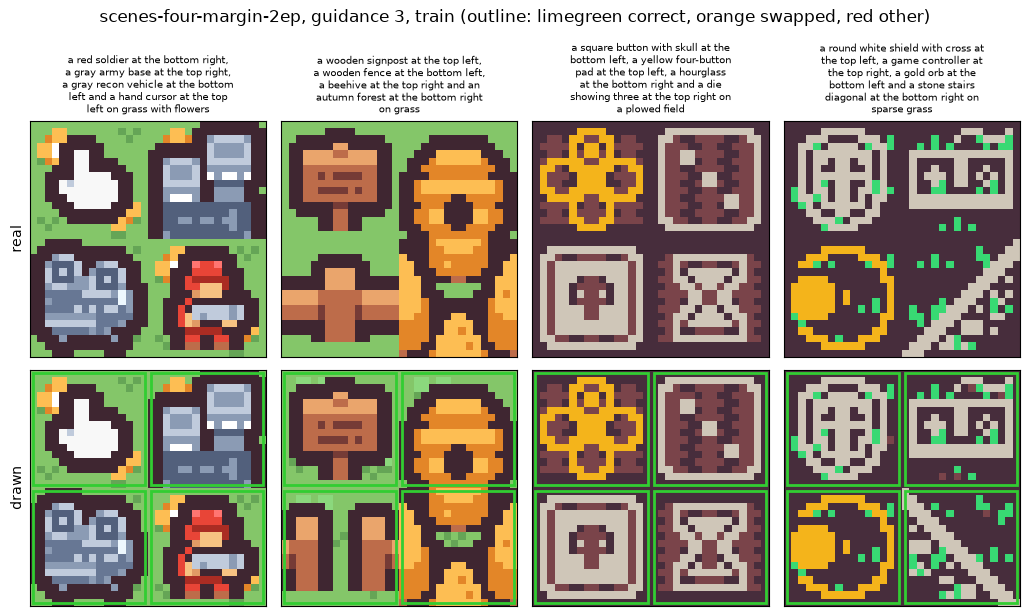

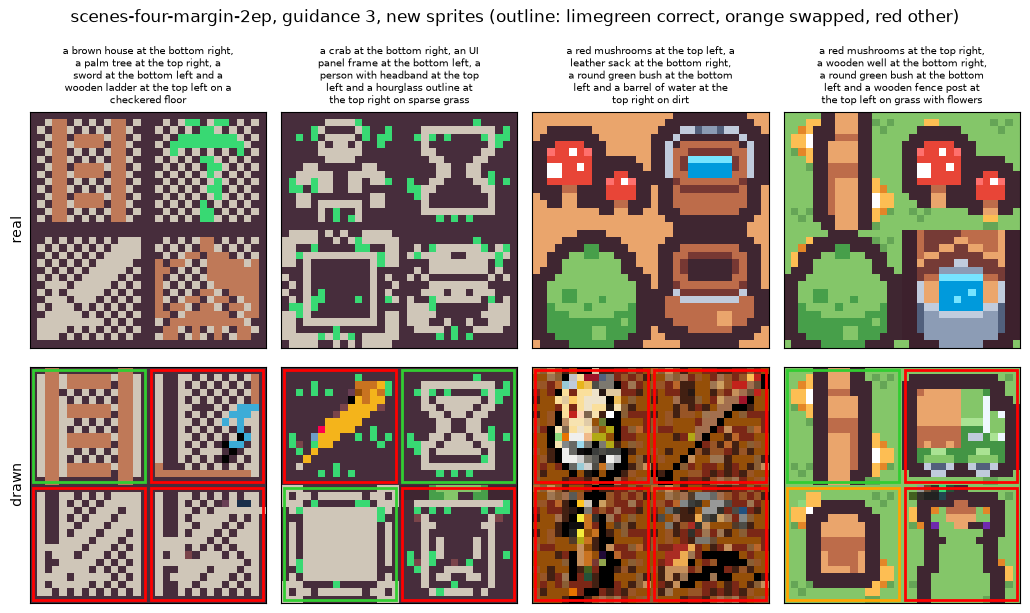

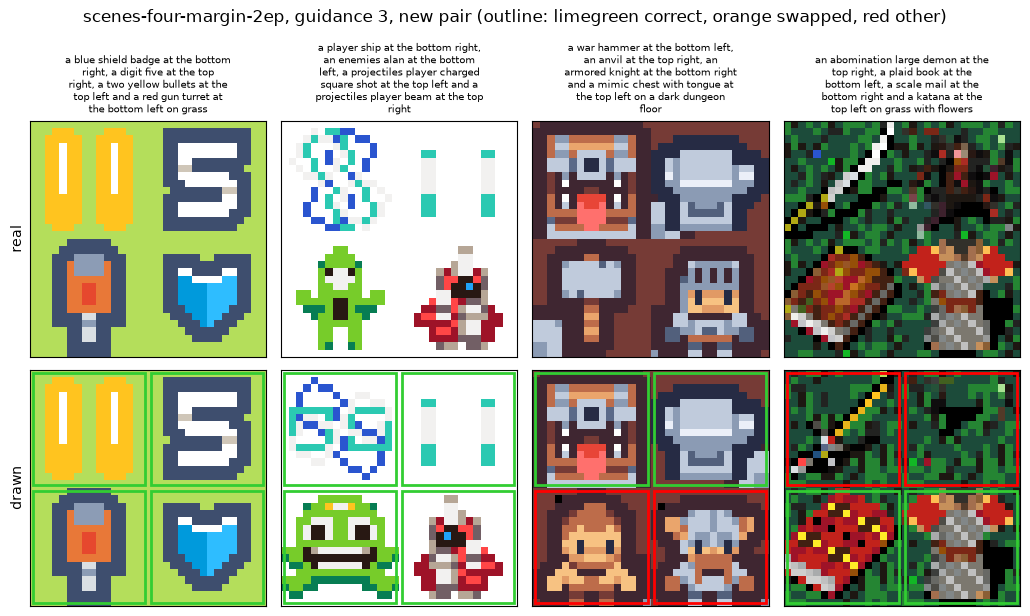

1.02 s per drawing in batches of 4 on mps; the sweep's 36,000 drawings at this rate: 10:14:15. Bigger batches and guidance 1 draw faster.


In [4]:
model, _ = load_model(ROOT.joinpath("checkpoints", TEST_RUN, "checkpoint.pt"), device)
seconds, count = 0.0, 0
for kind in KINDS:
    rows = np.flatnonzero(scenes.kinds == kind)[:TEST_SCENES]
    started = time.time()
    drawn = draw(model, [scenes.captions[i] for i in rows], TEST_GUIDANCE, samples=1, batch=BATCH)
    seconds, count = seconds + time.time() - started, count + len(rows)
    correct, swapped = classify(scores(quadrants(drawn), scenes.pictures[rows], scenes.backgrounds[rows]), MATCH)
    show(scenes.tokens[rows], drawn[0], correct[0], swapped[0], [scenes.captions[i] for i in rows],
         f"{TEST_RUN}, guidance {TEST_GUIDANCE:g}, {kind}")
total = len(RUNS) * len(GUIDANCES) * SAMPLES * len(scenes.captions)
print(f"{seconds / count:.2f} s per drawing in batches of {TEST_SCENES} on {device}; the sweep's {total:,} drawings "
      f"at this rate: {clock(total * seconds / count)}. Bigger batches and guidance 1 draw faster.")

## Placement

Every run in `RUNS` at every value in `GUIDANCES`. Drawings are saved in `OUT/<run>/` and reused, so running this again with another `MATCH`, or with more runs, draws only what is missing. The progress bar counts the drawings still to make, with the time left. The table is saved as `OUT/placement.csv`; the place columns are the share correct in each quadrant.

In [5]:
table: list[dict[str, float | int | str]] = []
matches: dict[tuple[str, float], np.ndarray] = {}  # scores() of each run and guidance value
saved = {
    (run, guidance): OUT.joinpath(run, f"guidance-{guidance:g}_per-kind-{PER_KIND}_samples-{SAMPLES}.npy")
    for run in RUNS
    for guidance in GUIDANCES
}
# Only drawings still to make count, so the rate and the time left are those of drawing. smoothing=0
# takes the rate over the whole sweep, which steadies the estimate across guidance values.
missing = sum(not path.exists() for path in saved.values())
with tqdm(total=missing * SAMPLES * len(scenes.captions), unit="drawing", smoothing=0) as progress:
    for run in RUNS:
        OUT.joinpath(run).mkdir(parents=True, exist_ok=True)
        model = None
        for guidance in GUIDANCES:
            path = saved[run, guidance]
            if path.exists():
                drawn = np.load(path)
            else:
                if model is None:
                    model, _ = load_model(ROOT.joinpath("checkpoints", run, "checkpoint.pt"), device)
                progress.set_description(f"{run}, guidance {guidance:g}")
                started = time.time()
                drawn = draw(model, scenes.captions, guidance, SAMPLES, BATCH, progress)
                np.save(path, drawn)
                progress.write(f"{run} guidance {guidance:g}: {drawn.shape[0] * drawn.shape[1]:,} drawings "
                               f"in {clock(time.time() - started)}")
            matches[run, guidance] = scores(quadrants(drawn), scenes.pictures, scenes.backgrounds)
            correct, swapped = classify(matches[run, guidance], MATCH)
            table += [{"run": run, "guidance": guidance, **row} for row in summary(correct, swapped, scenes.kinds)]
placement = pd.DataFrame(table)
placement.to_csv(OUT.joinpath("placement.csv"), index=False)
display(placement.round(3))
print("chance with the right four objects in random quadrants: 0.250 correct per quadrant, 0.042 all four")

  0%|          | 0/36000 [00:00<?, ?drawing/s]

KeyboardInterrupt: 

## Match scores

The best score of every drawn quadrant, one row per run and one column per kind, pooled over the guidance values; the dashed line is `MATCH`. Clear matches pile up near 1 and clear misses near 0, so scores far from `MATCH` do not depend on it. The table gives the share within 0.1 of `MATCH`: the quadrants whose label `MATCH` actually decides. Set `MATCH` in the valley between the two peaks, and rerun the placement cell, which redraws nothing.

In [ ]:
BINS = np.linspace(0, 1, 41)
NEAR = 0.1  # the table's band around MATCH
figure, axes = plt.subplots(len(RUNS), len(KINDS), figsize=(4 * len(KINDS), 2.4 * len(RUNS) + 0.6), sharex=True,
                            sharey=True, squeeze=False)
near: dict[str, dict[str, float]] = {kind: {} for kind in KINDS}
for row, run in zip(axes, RUNS):
    for axis, kind in zip(row, KINDS):
        best = np.concatenate([matches[run, guidance][:, scenes.kinds == kind].max(-1).ravel() for guidance in GUIDANCES])
        near[kind][run] = (np.abs(best - MATCH) < NEAR).mean()
        axis.hist(best, bins=BINS, color="#2a78d6", rwidth=0.85)
        axis.axvline(MATCH, color="0.35", linestyle="--", linewidth=1)
        axis.set_yscale("log")
        axis.set_title(f"{run}, {kind}", fontsize=9)
        axis.spines[["top", "right"]].set_visible(False)
for axis in axes[-1]:
    axis.set_xlabel("best match score")
for row in axes:
    row[0].set_ylabel("drawn quadrants")
figure.suptitle(f"Best match score per drawn quadrant, all guidance values (dashed: MATCH = {MATCH:g})")
figure.tight_layout()
plt.show()
display(pd.DataFrame(near).rename_axis(f"share within {NEAR:g} of MATCH").round(3))